# Model Building
### Objective:
Build classification models to predict the presence of heart disease using the cleaned and feature-selected dataset.


### Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve

In [30]:
df_model = pd.read_csv('E:/Heart_Disease_Predictor/data/processed/heart_disease_model.csv')
df_model.head()

,age,sex,cp,thalach,exang,oldpeak,ca,thal,target
0,63.0,1.0,1.0,150.0,0.0,2.3,0.0,6.0,0
1,67.0,1.0,4.0,108.0,1.0,1.5,3.0,3.0,1
2,67.0,1.0,4.0,129.0,1.0,2.6,2.0,7.0,1
3,37.0,1.0,3.0,187.0,0.0,3.5,0.0,3.0,0
4,41.0,0.0,2.0,172.0,0.0,1.4,0.0,3.0,0


In [31]:
df_model.columns

Index(['age', 'sex', 'cp', 'thalach', 'exang', 'oldpeak', 'ca', 'thal',
       'target'],
      dtype='object')

In [5]:
x = df_model.drop('target', axis=1)
y = df_model['target']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=9, stratify=y)

In [6]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(242, 8) (61, 8) (242,) (61,)


In [7]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### Logistic Regression

In [8]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)
y_pred_lr = lr.predict(x_test_scaled)

In [9]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.2f}")
print("classification_report:\n", classification_report(y_test, y_pred_lr))
print(f'\nConfusion Matrix: {confusion_matrix(y_test, y_pred_lr)}')

Accuracy: 0.72
classification_report:
               precision    recall  f1-score   support

           0       0.71      0.82      0.76        33
           1       0.74      0.61      0.67        28

    accuracy                           0.72        61
   macro avg       0.72      0.71      0.71        61
weighted avg       0.72      0.72      0.72        61


Confusion Matrix: [[27  6]
 [11 17]]


### Observations:

 - The model performs better at predicting Class 0 (No Heart Disease) than Class 1.

 - Recall for Class 1 (0.61) indicates it misses some positive cases (false negatives), which is critical in medical scenarios.

 - Overall, the model shows balanced performance for a baseline model, with room for improvement through:
   - Trying more complex models (e.g., Random Forest, XGBoost)

   - Hyperparameter tuning

   - Cross-validation

   - Handling class imbalance (if needed)

### Random Forest Classifier

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100,
                            max_depth=10,
                            min_samples_split=5,
                            min_samples_leaf=2,
                            random_state=9,
                            class_weight='balanced')
rf.fit(x_train_scaled, y_train)
y_pred_rf = rf.predict(x_test_scaled)

In [16]:
print(f'Accuracy: {accuracy_score(y_test, y_pred_rf):.2f}')
print("\n Classification Report:\n", classification_report(y_test, y_pred_rf))
print("\n Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.74

 Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.85      0.78        33
           1       0.77      0.61      0.68        28

    accuracy                           0.74        61
   macro avg       0.75      0.73      0.73        61
weighted avg       0.74      0.74      0.73        61


 Confusion Matrix:
 [[28  5]
 [11 17]]


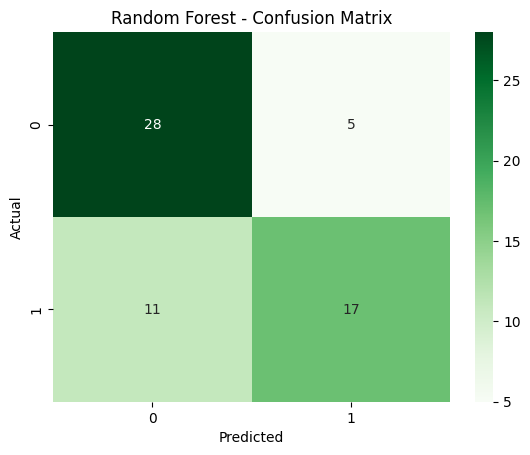

In [17]:
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

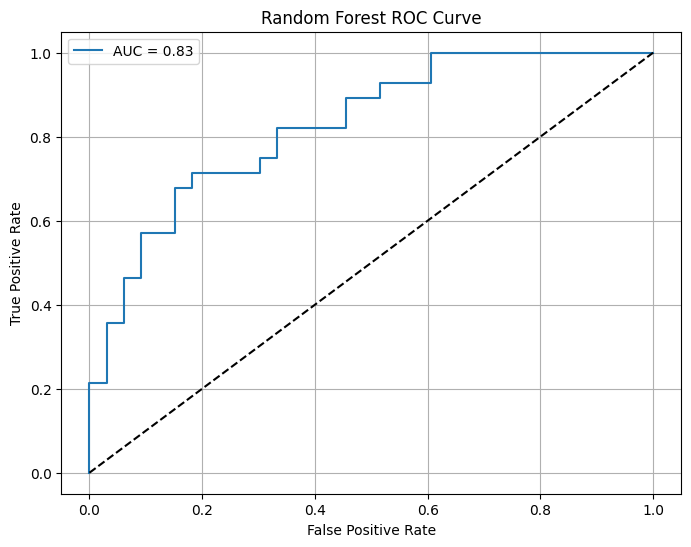

In [19]:
y_proba = rf.predict_proba(x_test_scaled)[:, 1]  # probability of class 1
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve')
plt.legend()
plt.grid()
plt.show()

 - The model performs better at identifying patients without heart disease (class 0) — recall = 0.85.

 - Recall for heart disease cases (class 1) is lower (0.61), indicating some patients with heart disease are missed.

 - Precision is fairly balanced between classes, indicating reliable predictions overall.

 - Balanced performance with room to improve sensitivity (recall) for heart disease detection.

###  Support Vector Machine (SVM) - RBF Kernel

In [32]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf',
          C=10,
          gamma='scale',
          class_weight='balanced',
          probability=True,
          random_state=9)

svm.fit(x_train_scaled, y_train)
y_pred_svm = svm.predict(x_test_scaled)

In [33]:
print(f'Accuracy: {accuracy_score(y_test, y_pred_svm):.2f}')
print(f'\nClassification Report:\n {classification_report(y_test, y_pred_svm)}')
print(f'\nConfusion Matrix:\n {confusion_matrix(y_test, y_pred_svm)}')

Accuracy: 0.77

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.82      0.79        33
           1       0.77      0.71      0.74        28

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61


Confusion Matrix:
 [[27  6]
 [ 8 20]]


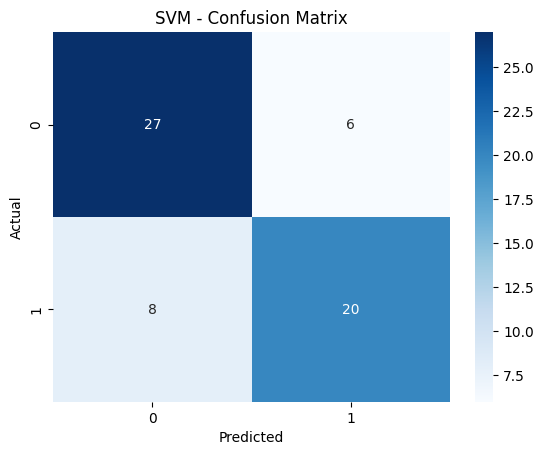

In [25]:
cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### Observations

 - Model is slightly better at predicting no heart disease (class 0).

 - Balanced performance overall, with better recall than Logistic Regression or Random Forest for both classes.

 - Useful in clinical cases where reducing false negatives (missed disease cases) is important.

### Decision Tree Classifier

In [28]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=9,
    class_weight='balanced'
)
dt.fit(x_train_scaled, y_train)
y_pred_dt = dt.predict(x_test_scaled)

In [29]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.2f}")
print(f'\nClassification Report:\n {classification_report(y_test, y_pred_dt)}')
print(f'\nConfusion Matrix:\n {confusion_matrix(y_test, y_pred_dt)}')

Accuracy: 0.72

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.82      0.76        33
           1       0.74      0.61      0.67        28

    accuracy                           0.72        61
   macro avg       0.72      0.71      0.71        61
weighted avg       0.72      0.72      0.72        61


Confusion Matrix:
 [[27  6]
 [11 17]]


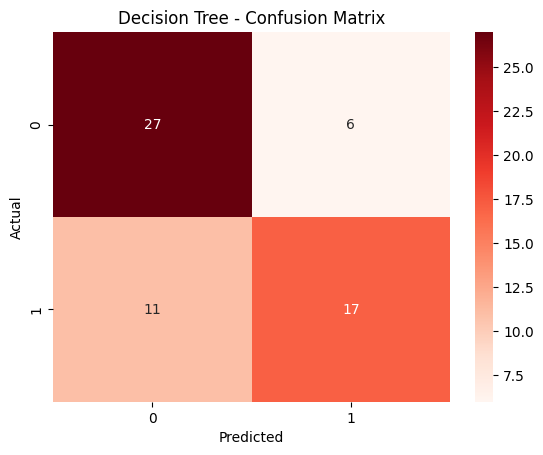

In [31]:
cm = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

 - Decision Tree shows moderate accuracy but struggles with recall on heart disease cases.

 - It may be overfitting slightly or limited by shallow depth.

 - Consider:
   - Trying ensemble methods like Random Forest or XGBoost.

   - Performing hyperparameter tuning with GridSearchCV.

   - Visualizing the tree to understand decision boundaries.

### XGBoost (Extreme Gradient Boosting)

In [35]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=9,
    eval_metric='logloss'
)
xgb.fit(x_train_scaled, y_train)
y_pred_xgb = xgb.predict(x_test_scaled)

In [36]:
print(f'Accuracy: {accuracy_score(y_test, y_pred_xgb):.2f}')
print(f'\nClassification Report:\n {classification_report(y_test, y_pred_xgb)}')
print(f'\nConfusion Matrix: \n {confusion_matrix(y_test, y_pred_xgb)}')

Accuracy: 0.72

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.82      0.76        33
           1       0.74      0.61      0.67        28

    accuracy                           0.72        61
   macro avg       0.72      0.71      0.71        61
weighted avg       0.72      0.72      0.72        61


Confusion Matrix: 
 [[27  6]
 [11 17]]


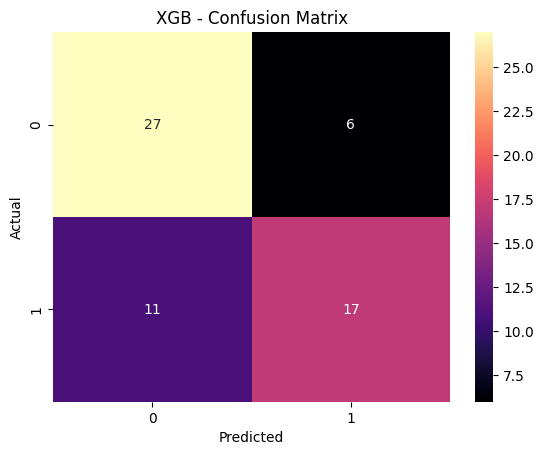

In [37]:
cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='magma')
plt.title("XGB - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### K-Nearest Neighbors (KNN) Model

In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5) 
knn.fit(x_train_scaled, y_train)
y_pred_knn = knn.predict(x_test_scaled)

In [12]:
print(f'Accuracy: {accuracy_score(y_test, y_pred_knn):.2f}')
print('\nClassification Report:\n', classification_report(y_test, y_pred_knn))
print('\nConfusion Matrix:\n', confusion_matrix(y_test, y_pred_knn))

Accuracy: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.88      0.79        33
           1       0.81      0.61      0.69        28

    accuracy                           0.75        61
   macro avg       0.77      0.74      0.74        61
weighted avg       0.76      0.75      0.75        61


Confusion Matrix:
 [[29  4]
 [11 17]]


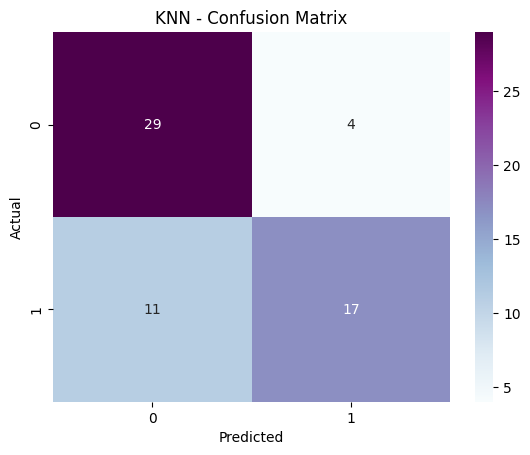

In [16]:
cm = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm, annot=True, fmt='d', cmap='BuPu')
plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

 - Good overall accuracy and precision.

 - Lower recall for heart disease cases (Class 1) suggests the model may miss some at-risk patients.

 - May benefit from hyperparameter tuning (GridSearchCV) to improve balance.



### Lightgbm 

In [18]:
from lightgbm import LGBMClassifier

# Ensure consistent DataFrame use
x_train_df = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_df = pd.DataFrame(x_test_scaled, columns=x_train.columns)

lgbm = LGBMClassifier(
    learning_rate=0.05,
    num_leaves=31,
    min_data_in_leaf=1,
    max_depth=-1,
    n_estimators=100, 
    random_state=9
)

# Fit the model
lgbm.fit(x_train_df, y_train)

# Predict
y_pred_lgbm = lgbm.predict(x_test_df)

# Evaluate
print(f"Accuracy: {accuracy_score(y_test, y_pred_lgbm):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lgbm))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lgbm))


[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Info] Number of positive: 111, number of negative: 131
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000149 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 138
[LightGBM] [Info] Number of data points in the train set: 242, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.458678 -> initscore=-0.165667
[LightGBM] [Info] Start training from score -0.165667
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
Accuracy: 0.75

Classification Report:
               precision    recall  f1-score   supp

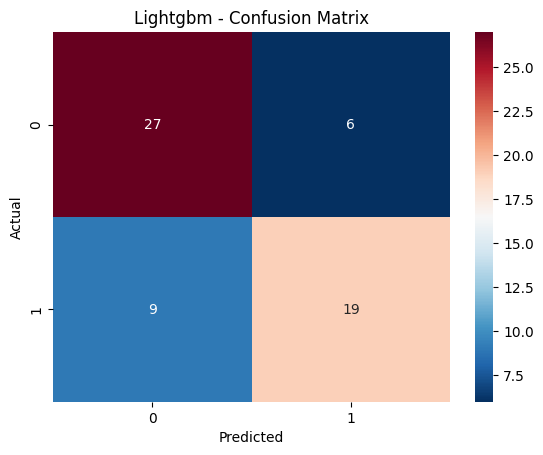

In [20]:
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(cm, annot=True, fmt='d', cmap='RdBu_r')
plt.title("Lightgbm - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Model Performance Summary Table 

| Model             | Accuracy | Precision (avg) | Recall (avg) | F1-score (avg) |
| ----------------- | -------- | --------------- | ------------ | -------------- |
| **SVM**           | 0.77     | 0.77            | 0.77         | 0.77           |
| **LightGBM**      | 0.75     | 0.76            | 0.75         | 0.75           |
| **KNN**           | 0.75     | 0.77            | 0.74         | 0.74           |
| **Random Forest** | 0.74     | 0.75            | 0.73         | 0.73           |
| **Logistic Reg.** | 0.72     | 0.72            | 0.71         | 0.71           |
| **Decision Tree** | 0.72     | 0.72            | 0.71         | 0.71           |
| **XGBoost**       | 0.72     | 0.72            | 0.71         | 0.71           |


### Model comparison

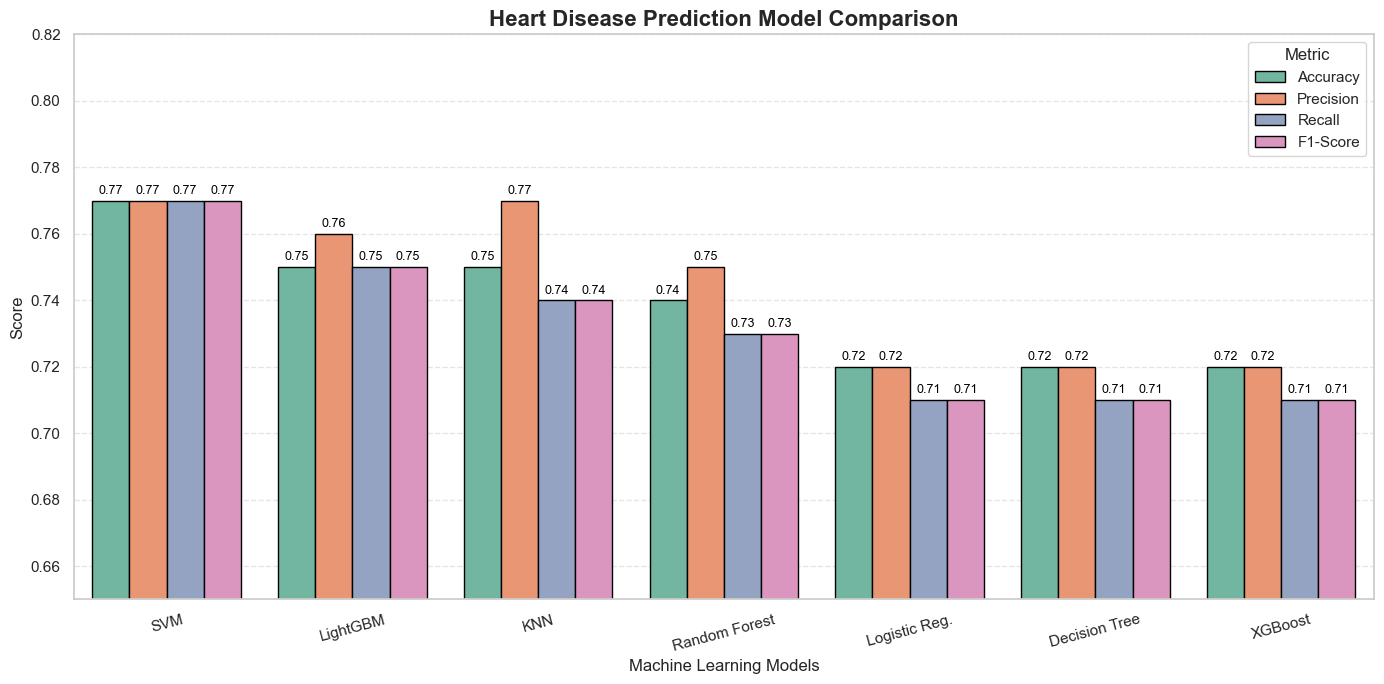

In [59]:
models = ['SVM', 'LightGBM', 'KNN', 'Random Forest', 'Logistic Reg.', 'Decision Tree', 'XGBoost']
accuracy = [0.77, 0.75, 0.75, 0.74, 0.72, 0.72, 0.72]
precision = [0.77, 0.76, 0.77, 0.75, 0.72, 0.72, 0.72]
recall = [0.77, 0.75, 0.74, 0.73, 0.71, 0.71, 0.71]
f1 = [0.77, 0.75, 0.74, 0.73, 0.71, 0.71, 0.71]

df = pd.DataFrame({
    'Model': models * 4,
    'Metric': ['Accuracy'] * 7 + ['Precision'] * 7 + ['Recall'] * 7 + ['F1-Score'] * 7,
    'Score': accuracy + precision + recall + f1
})

# Set the theme
sns.set(style='whitegrid')
plt.figure(figsize=(14, 7))

# Plot using seaborn
ax = sns.barplot(data=df, x='Model', y='Score', hue='Metric', palette='Set2', edgecolor='black')

# Add value labels on bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=9, color='black', xytext=(0, 7),
                textcoords='offset points')

# Improve the plot
plt.title('Heart Disease Prediction Model Comparison', fontsize=16, fontweight='bold')
plt.ylim(0.65, 0.82)
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=15)
plt.legend(title='Metric')
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


In [34]:
import joblib

joblib.dump(svm, '/Heart_Disease_Predictor/models/best_model.pkl')

['/Heart_Disease_Predictor/models/best_model.pkl']

In [29]:
joblib.dump(scaler, '/Heart_Disease_Predictor/models/scaler.pkl')

['/Heart_Disease_Predictor/models/scaler.pkl']